## 1. Setup and Imports

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix

try:
    from tensorflow.keras import mixed_precision
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_global_policy(policy)
    print("✅ Mixed precision enabled (float16) for faster training")
except:
    print("ℹ️  Mixed precision not available, using default float32")

print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

✅ Mixed precision enabled (float16) for faster training
TensorFlow version: 2.20.0
Keras version: 3.12.0
GPU Available: []


## 2. Dataset Exploration

Total medications: 14

Medications: ['acetaminophen', 'amlodipine', 'amoxicillin', 'aspirin', 'atorvastatin', 'gabapentin', 'hydrochlorothiazide', 'ibuprofen', 'levothyroxine', 'lisinopril', 'metformin', 'metoprolol', 'omeprazole', 'sertraline']


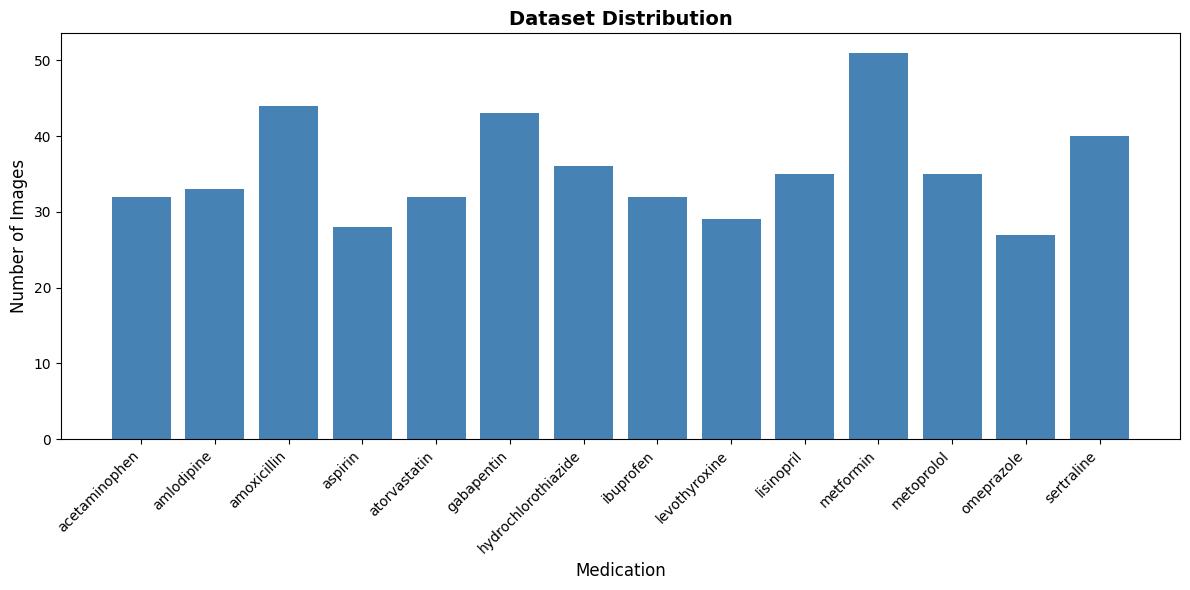


Total images: 497
Min images per class: 27
Max images per class: 51
Average images per class: 35.5


In [10]:

DATASET_PATH = Path("data/pills_dataset")

medications = sorted([d.name for d in DATASET_PATH.iterdir() if d.is_dir()])
print(f"Total medications: {len(medications)}")
print(f"\nMedications: {medications}")


image_counts = {}
for med in medications:
    images = list((DATASET_PATH / med).glob("*.[jp][pn]g"))
    image_counts[med] = len(images)

plt.figure(figsize=(12, 6))
plt.bar(image_counts.keys(), image_counts.values(), color='steelblue')
plt.xlabel('Medication', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.title('Dataset Distribution', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"\nTotal images: {sum(image_counts.values())}")
print(f"Min images per class: {min(image_counts.values())}")
print(f"Max images per class: {max(image_counts.values())}")
print(f"Average images per class: {sum(image_counts.values()) / len(image_counts):.1f}")

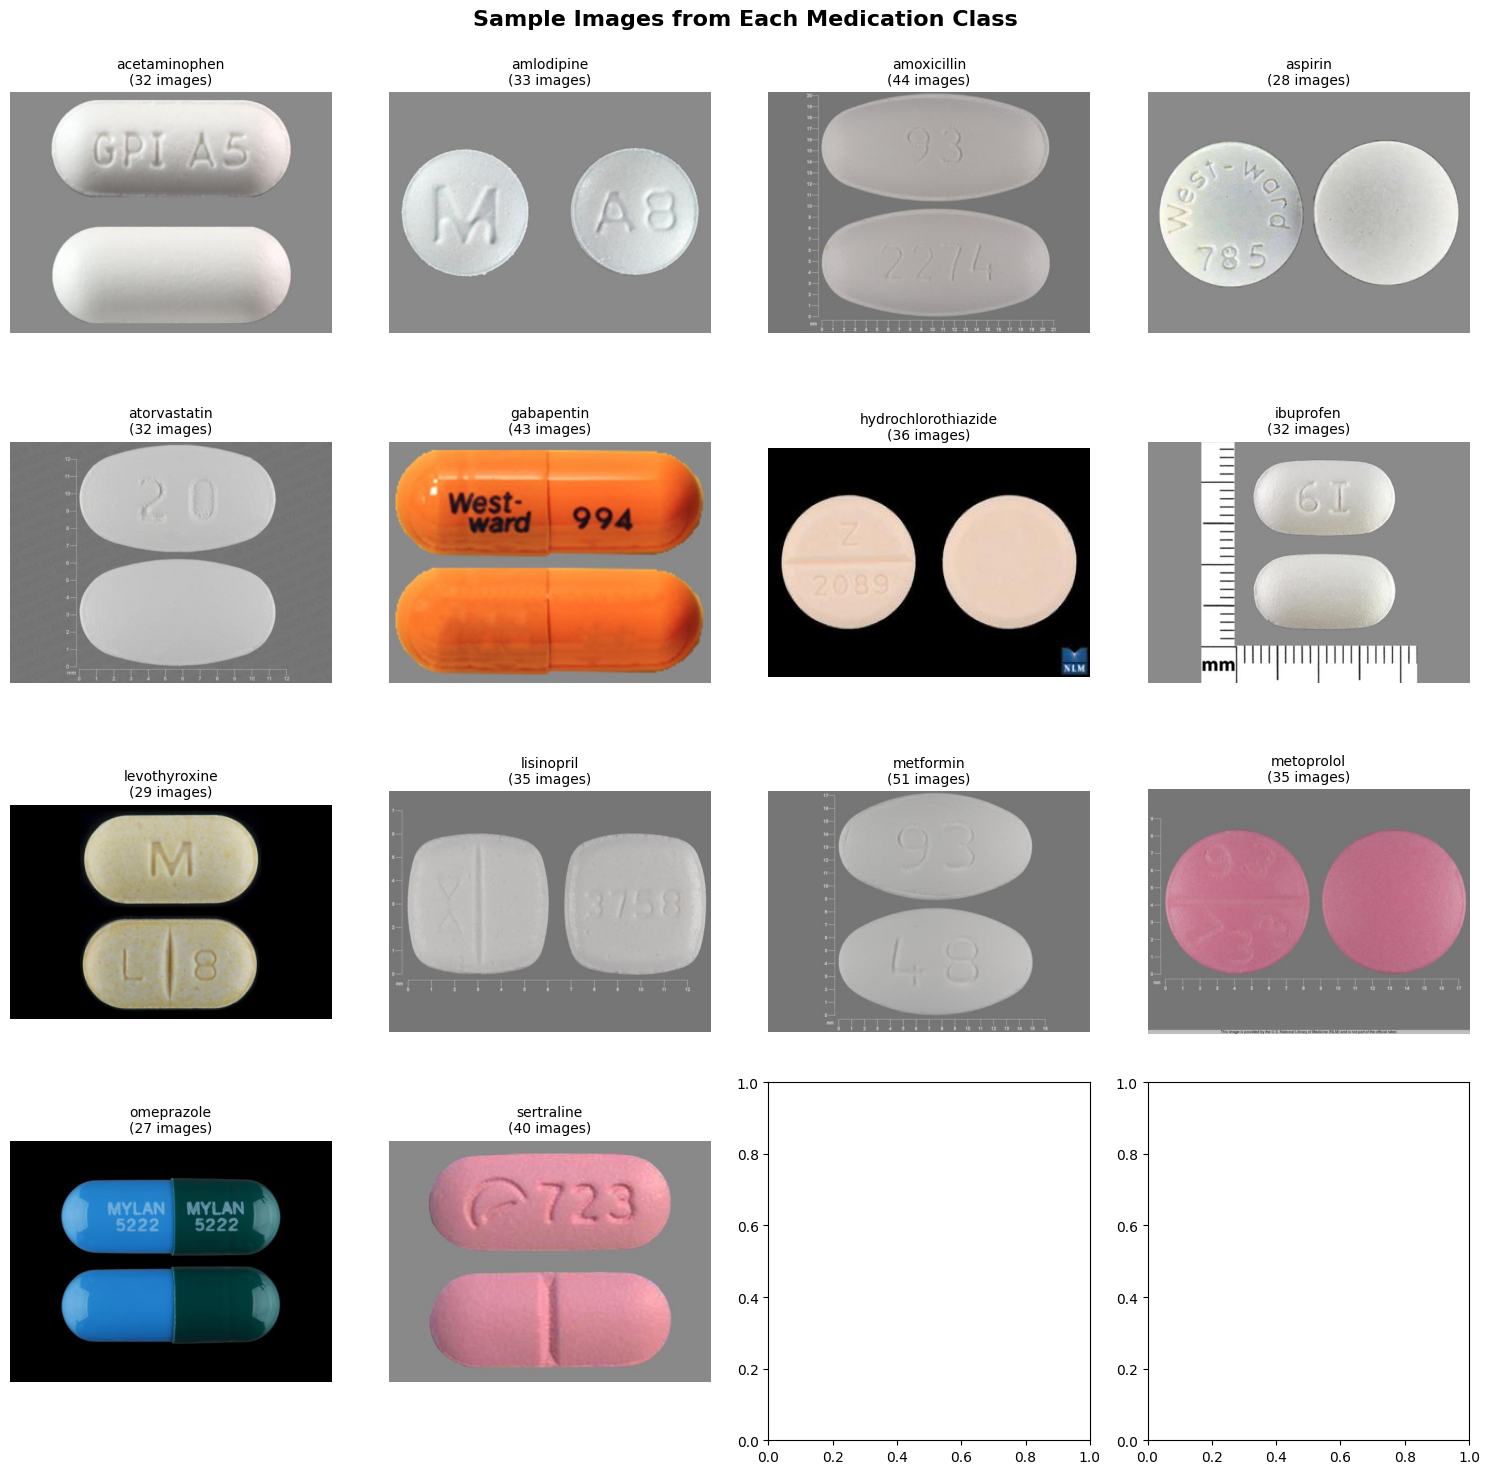

In [11]:

fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.flatten()

for idx, med in enumerate(medications[:14]):
    images = list((DATASET_PATH / med).glob("*.[jp][pn]g"))
    if images:
        img = Image.open(images[0])
        axes[idx].imshow(img)
        axes[idx].set_title(f"{med}\n({len(images)} images)", fontsize=10)
        axes[idx].axis('off')

plt.suptitle('Sample Images from Each Medication Class', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

In [12]:

IMG_SIZE = (299, 299)
BATCH_SIZE = 16  
VALIDATION_SPLIT = 0.15
TEST_SPLIT = 0.1
SEED = 42


train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VALIDATION_SPLIT + TEST_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

val_test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VALIDATION_SPLIT + TEST_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)


val_size = int(len(val_test_ds) * 0.67)  
val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)

class_names = train_ds.class_names
num_classes = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print(f"Training batches: {len(train_ds)}")
print(f"Validation batches: {len(val_ds)}")
print(f"Test batches: {len(test_ds)}")
print(f"Number of classes: {num_classes}")
print("✅ Performance optimization: caching and prefetching enabled")

Found 738 files belonging to 14 classes.
Using 554 files for training.
Using 554 files for training.
Found 738 files belonging to 14 classes.
Using 184 files for validation.
Found 738 files belonging to 14 classes.
Using 184 files for validation.
Training batches: 35
Validation batches: 8
Test batches: 4
Number of classes: 14
✅ Performance optimization: caching and prefetching enabled
Training batches: 35
Validation batches: 8
Test batches: 4
Number of classes: 14
✅ Performance optimization: caching and prefetching enabled


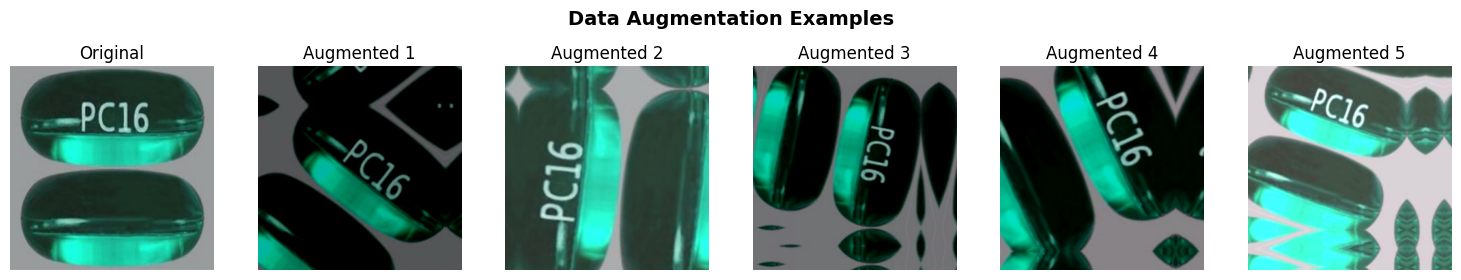

In [13]:

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3), 
    layers.RandomZoom(0.3),  
    layers.RandomTranslation(0.2, 0.2),  
    layers.RandomContrast(0.3),  
    layers.RandomBrightness(0.3), 
], name="augmentation")


plt.figure(figsize=(15, 5))
for images, labels in train_ds.take(1):
    first_image = images[0]
    for i in range(6):
        ax = plt.subplot(2, 6, i + 1)
        if i == 0:
            plt.imshow(first_image.numpy().astype("uint8"))
            plt.title("Original")
        else:
            augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
            plt.imshow(augmented_image[0].numpy().astype("uint8"))
            plt.title(f"Augmented {i}")
        plt.axis("off")

plt.suptitle('Data Augmentation Examples', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Model Architecture

In [14]:
def build_model(num_classes):
    """Build MobileNetV2-based transfer learning model with enhanced architecture"""
    
    
    base_model = keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  
    
    
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    
    
    x = data_augmentation(inputs)
    
    
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    
    
    x = base_model(x, training=False)
    
   
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
   
    x = layers.Dense(512, activation='relu', 
                     kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
   
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    
    x = layers.Dense(128, activation='relu',
                     kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    

    model = keras.Model(inputs, outputs, name='pill_mobilenetv2')
    model.summary()

    return model, base_model

model, base_model = build_model(num_classes)

Model: "pill_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 10, 10, 1280)   │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 14)             │         1,806 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,088,078 (11.78 MB)

 Trainable params: 825,998 (3.15 MB)

 Non-trainable params: 2,262,080 (8.63 MB)

## 5. Calculate Class Weights

In [15]:

y_train = np.concatenate([y for x, y in train_ds], axis=0)
class_counts = np.bincount(y_train.astype(int))
total_samples = len(y_train)
class_weights = {i: total_samples / (num_classes * count) 
                for i, count in enumerate(class_counts)}

print("Class weights:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.2f}")

Class weights:
acetaminophen: 1.10
amlodipine: 1.01
amoxicillin: 0.97
aspirin: 0.94
atorvastatin: 1.41
gabapentin: 0.68
hydrochlorothiazide: 1.04
ibuprofen: 1.20
levothyroxine: 0.84
lisinopril: 0.97
metformin: 0.99
metoprolol: 1.01
omeprazole: 1.13
sertraline: 1.07


## 6. Model Training - Phase 1 (Frozen Base)

In [ ]:

model.compile(
    optimizer=keras.optimizers.Adam(1e-3), 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    min_delta=0.005, 
    mode='max'
)


reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)


import datetime
log_dir = f"logs/fit/{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}"
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1,
    write_graph=True,
    update_freq='epoch'
)


checkpoint = keras.callbacks.ModelCheckpoint(
    'models/trained_models/checkpoint_pill_mobilenetv2.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

EPOCHS_FROZEN = 50
print(f"📊 TensorBoard logs will be saved to: {log_dir}")
print("   Run 'tensorboard --logdir logs/fit' to visualize training")

print("\n" + "="*60)
print("PHASE 1: Training with frozen base model")
print("="*60 + "\n")

history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FROZEN,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr, tensorboard_callback, checkpoint],
    verbose=1
)

📊 TensorBoard logs will be saved to: logs/fit/20251202-143410
   Run 'tensorboard --logdir logs/fit' to visualize training

PHASE 1: Training with frozen base model

Epoch 1/50
Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5124 - loss: 5.8780
Epoch 1: val_accuracy improved from None to 0.52344, saving model to models/trained_models/checkpoint_pill_mobilenetv2.keras

Epoch 1: val_accuracy improved from None to 0.52344, saving model to models/trained_models/checkpoint_pill_mobilenetv2.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 171s 5s/step - accuracy: 0.4603 - loss: 5.9109 - val_accuracy: 0.5234 - val_loss: 5.8604 - learning_rate: 0.0010
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 171s 5s/step - accuracy: 0.4603 - loss: 5.9109 - val_accuracy: 0.5234 - val_loss: 5.8604 - learning_rate: 0.0010
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4541 - loss: 5.6916
Epoch 2: val_accuracy did not improve from 0.52344
35/35 ━━━━━━━━━━━━━━━━━━━━ 158s 5s/step - accuracy: 0.4585 - los

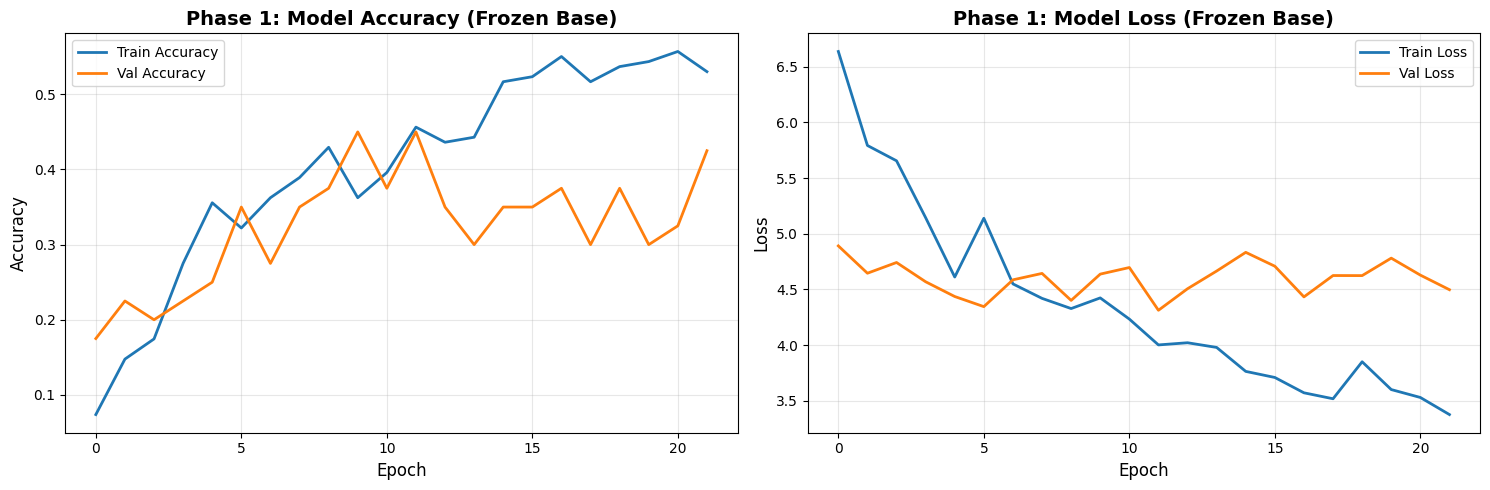

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))


ax1.plot(history_frozen.history['accuracy'], label='Train Accuracy', linewidth=2)
ax1.plot(history_frozen.history['val_accuracy'], label='Val Accuracy', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Phase 1: Model Accuracy (Frozen Base)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(history_frozen.history['loss'], label='Train Loss', linewidth=2)
ax2.plot(history_frozen.history['val_loss'], label='Val Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('Phase 1: Model Loss (Frozen Base)', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Model Training - Phase 2 (Fine-tuning)

In [ ]:

base_model.trainable = True
fine_tune_at = 50  

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False


model.compile(
    optimizer=keras.optimizers.Adam(5e-5), 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Total layers: {len(base_model.layers)}")
print(f"Trainable layers: {sum([layer.trainable for layer in base_model.layers])}")


EPOCHS_FINETUNE = 50

print("\n" + "="*60)
print("PHASE 2: Fine-tuning with unfrozen top layers")
print("="*60 + "\n")

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINETUNE,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr, tensorboard_callback, checkpoint],
    verbose=1
)

Total layers: 154
Trainable layers: 104

PHASE 2: Fine-tuning with unfrozen top layers

Epoch 1/50
Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 28s/step - accuracy: 0.3530 - loss: 6.2640 
Epoch 1: val_accuracy did not improve from 0.52344
35/35 ━━━━━━━━━━━━━━━━━━━━ 1026s 29s/step - accuracy: 0.3412 - loss: 6.2635 - val_accuracy: 0.4609 - val_loss: 6.0037 - learning_rate: 5.0000e-05
Epoch 2/50

Epoch 1: val_accuracy did not improve from 0.52344
35/35 ━━━━━━━━━━━━━━━━━━━━ 1026s 29s/step - accuracy: 0.3412 - loss: 6.2635 - val_accuracy: 0.4609 - val_loss: 6.0037 - learning_rate: 5.0000e-05
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 32s/step - accuracy: 0.3393 - loss: 6.1703 
Epoch 2: val_accuracy did not improve from 0.52344
35/35 ━━━━━━━━━━━━━━━━━━━━ 1133s 33s/step - accuracy: 0.3736 - loss: 6.0715 - val_accuracy: 0.3906 - val_loss: 6.2532 - learning_rate: 5.0000e-05
Epoch 3/50

Epoch 2: val_accuracy did not improve from 0.52344
35/35 ━━━━━━━━━━━━━━━━━━━━ 1133s 33s/step - accuracy: 0.3736 - lo

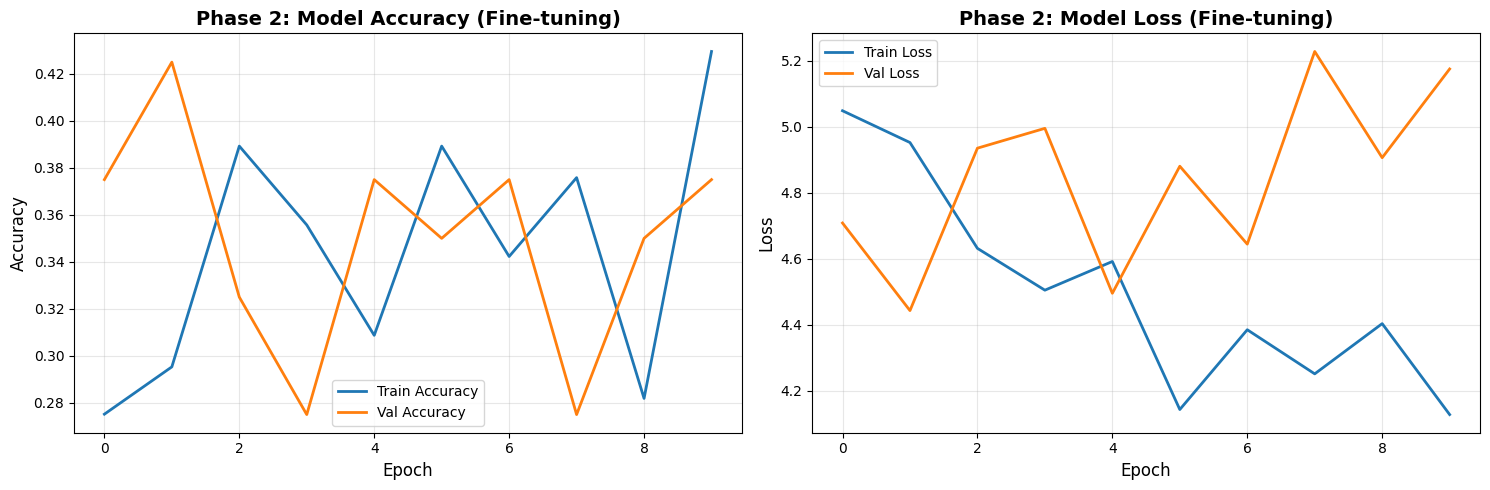

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))


ax1.plot(history_finetune.history['accuracy'], label='Train Accuracy', linewidth=2)
ax1.plot(history_finetune.history['val_accuracy'], label='Val Accuracy', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Phase 2: Model Accuracy (Fine-tuning)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)


ax2.plot(history_finetune.history['loss'], label='Train Loss', linewidth=2)
ax2.plot(history_finetune.history['val_loss'], label='Val Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('Phase 2: Model Loss (Fine-tuning)', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Model Evaluation

In [ ]:

print("\n" + "="*60)
print("EVALUATING MODEL ON TEST SET")
print("="*60 + "\n")

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy: {test_accuracy*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


EVALUATING MODEL ON TEST SET

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - accuracy: 0.3478 - loss: 4.5659
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - accuracy: 0.3478 - loss: 4.5659

Test Accuracy: 34.78%
Test Loss: 4.5659

Test Accuracy: 34.78%
Test Loss: 4.5659


In [ ]:

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)


unique_labels = np.unique(np.concatenate([y_true, y_pred]))
present_class_names = [class_names[i] for i in unique_labels]

print("\nClassification Report:")
print("="*80)
print(f"Note: Only {len(unique_labels)} out of {num_classes} classes present in test set")
print("="*80)
print(classification_report(y_true, y_pred, labels=unique_labels, target_names=present_class_names, zero_division=0))


Classification Report:
Note: Only 14 out of 14 classes present in test set
                     precision    recall  f1-score   support

      acetaminophen       0.33      0.33      0.33         3
         amlodipine       1.00      0.33      0.50         3
        amoxicillin       0.00      0.00      0.00         1
            aspirin       0.00      0.00      0.00         2
       atorvastatin       0.00      0.00      0.00         1
         gabapentin       0.00      0.00      0.00         1
hydrochlorothiazide       1.00      0.33      0.50         3
          ibuprofen       0.00      0.00      0.00         3
      levothyroxine       1.00      1.00      1.00         1
         lisinopril       0.00      0.00      0.00         0
          metformin       0.00      0.00      0.00         1
         metoprolol       0.00      0.00      0.00         0
         omeprazole       0.00      0.00      0.00         1
         sertraline       0.50      0.33      0.40         3

       

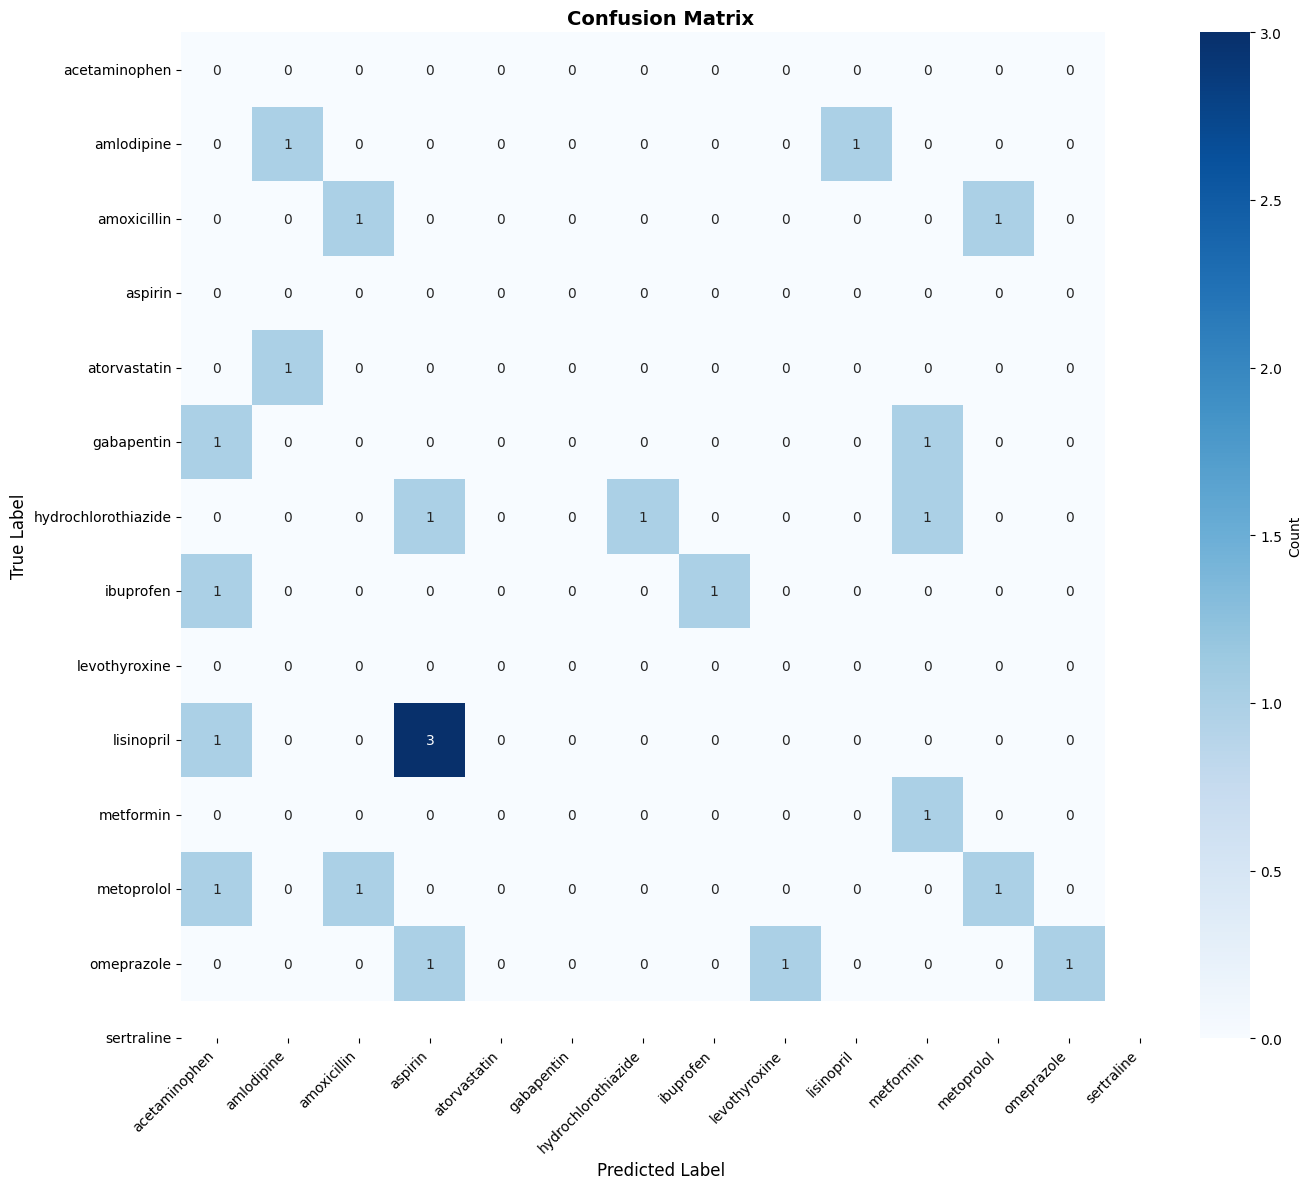

In [ ]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Save Model

In [ ]:

MODEL_PATH = Path("models/trained_models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

model_file = MODEL_PATH / "pill_mobilenetv2.keras"
labels_file = MODEL_PATH / "pill_mobilenetv2_labels.json"

model.save(model_file)
print(f"Model saved to: {model_file}")


with open(labels_file, 'w') as f:
    json.dump({"class_names": class_names}, f, indent=2)
print(f"Labels saved to: {labels_file}")


model_size_mb = model_file.stat().st_size / (1024 * 1024)
print(f"Model size: {model_size_mb:.2f} MB")

Model saved to: models\trained_models\pill_mobilenetv2.keras
Labels saved to: models\trained_models\pill_mobilenetv2_labels.json
Model size: 23.56 MB


## 10. Test Predictions on Sample Images

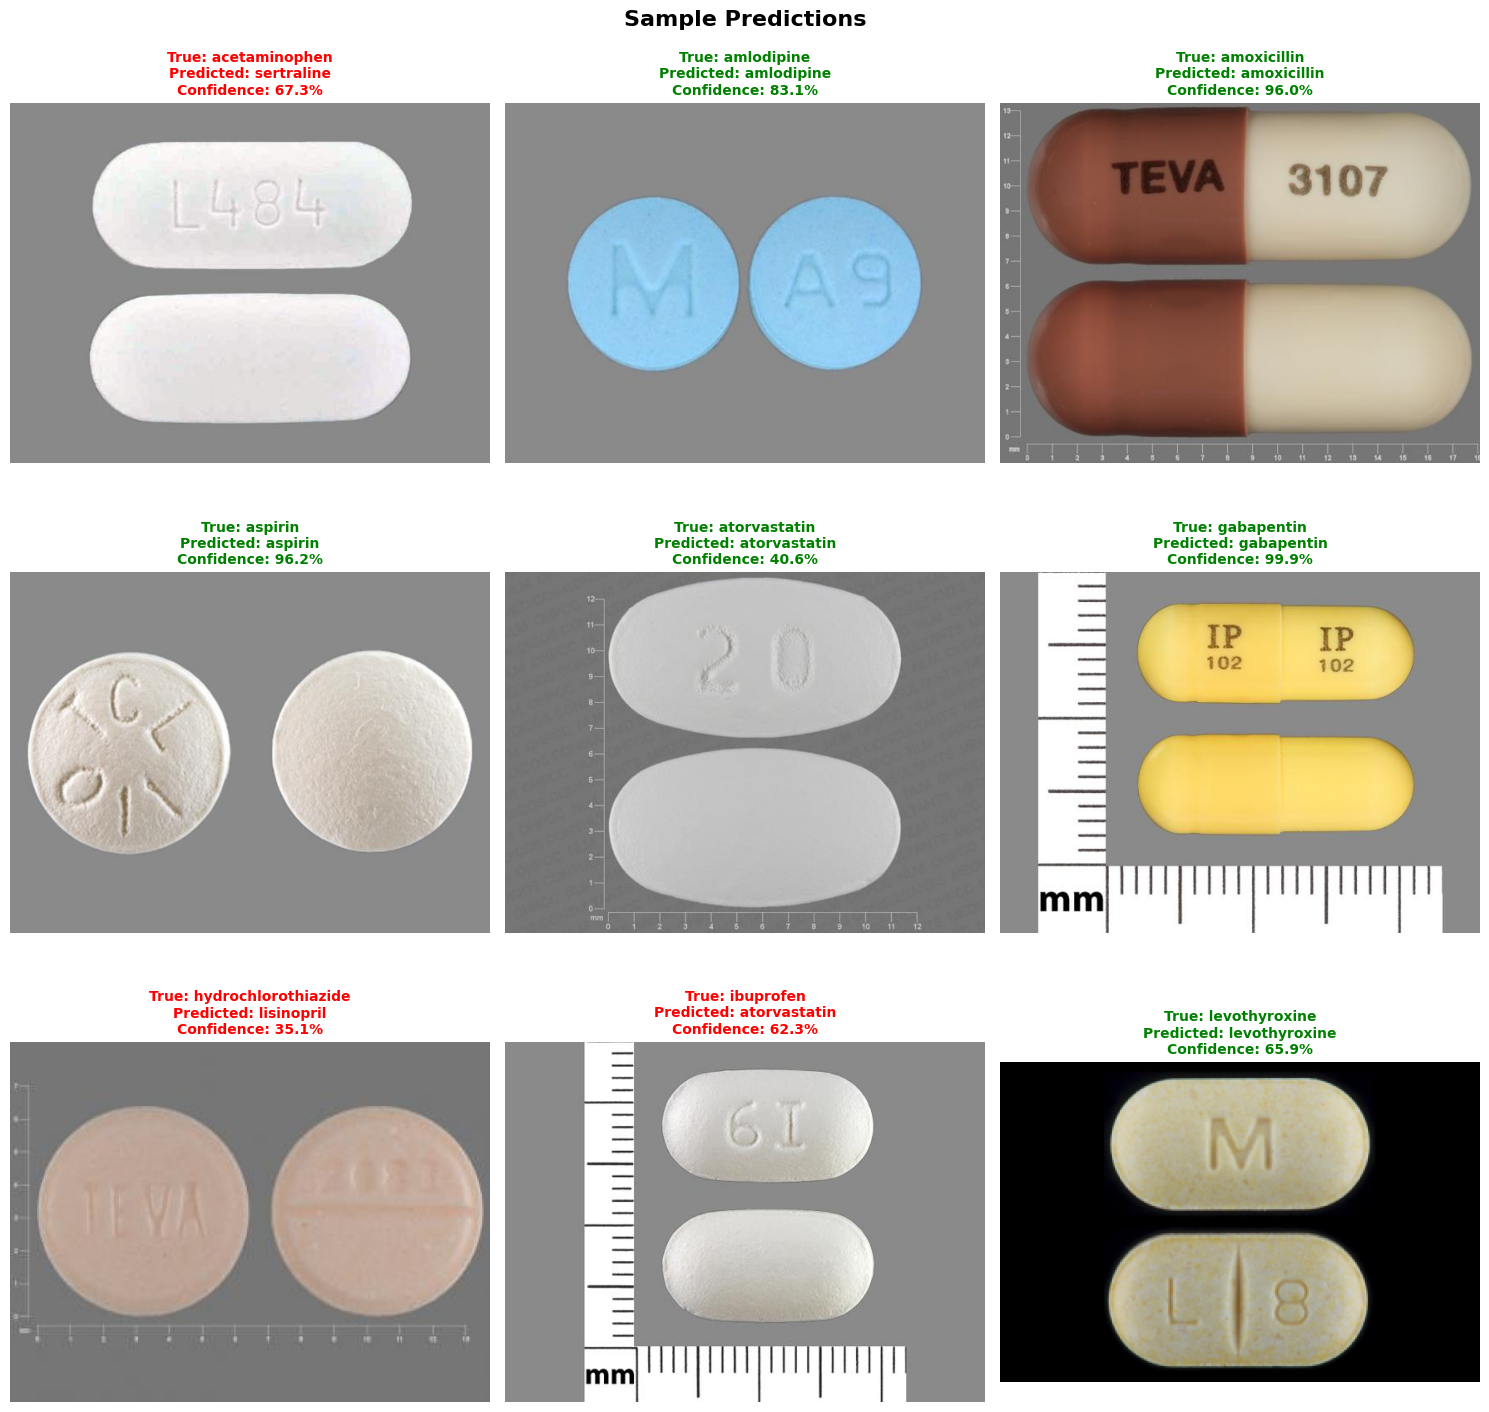

In [ ]:
def predict_pill(image_path, model, class_names):
    """Predict medication from image"""
  
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    
   
    predictions = model.predict(img_array, verbose=0)
    confidence = np.max(predictions[0]) * 100
    predicted_class = class_names[np.argmax(predictions[0])]
    
    return predicted_class, confidence, predictions[0]


fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

sample_count = 0
for med in medications[:9]:
    images = list((DATASET_PATH / med).glob("*.[jp][pn]g"))
    if images and sample_count < 9:
        img_path = images[0]
        predicted_class, confidence, probs = predict_pill(img_path, model, class_names)
        
       
        img = Image.open(img_path)
        axes[sample_count].imshow(img)
        
        
        title_color = 'green' if predicted_class == med else 'red'
        axes[sample_count].set_title(
            f"True: {med}\nPredicted: {predicted_class}\nConfidence: {confidence:.1f}%",
            fontsize=10, color=title_color, fontweight='bold'
        )
        axes[sample_count].axis('off')
        sample_count += 1

plt.suptitle('Sample Predictions', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 11. Drug Interaction Checker

In [ ]:

INTERACTIONS_FILE = Path("data/sample_interactions.json")

if INTERACTIONS_FILE.exists():
    with open(INTERACTIONS_FILE, 'r') as f:
        data = json.load(f)
        
        interactions_db = data.get('pairs', [])
else:
    interactions_db = []

print(f"Loaded {len(interactions_db)} drug interactions")

def check_drug_interactions(drug1, drug2, interactions_db):
    """Check for interactions between two drugs"""
    drug1_lower = drug1.lower()
    drug2_lower = drug2.lower()
    
    for interaction in interactions_db:
        
        drug_a = interaction.get('a', '').lower()
        drug_b = interaction.get('b', '').lower()
        
       
        if (drug1_lower == drug_a and drug2_lower == drug_b) or \
           (drug1_lower == drug_b and drug2_lower == drug_a):
            return interaction
    return None


drug1 = "aspirin"
drug2 = "ibuprofen"

interaction = check_drug_interactions(drug1, drug2, interactions_db)
if interaction:
    print(f"\n⚠️  INTERACTION FOUND between {drug1} and {drug2}")
    print(f"Severity: {interaction['severity']}")
    print(f"Description: {interaction['description']}")
else:
    print(f"\n✅ No known interactions between {drug1} and {drug2}")


Loaded 20 drug interactions

⚠️  INTERACTION FOUND between aspirin and ibuprofen
Severity: major
Description: Concurrent use may increase bleeding risk due to additive antiplatelet and NSAID effects. Aspirin's cardioprotective effects may be reduced.


## 12. Drug Information Lookup

In [ ]:

DRUG_INFO_FILE = Path("data/drug_information.json")

if DRUG_INFO_FILE.exists():
    with open(DRUG_INFO_FILE, 'r') as f:
        drug_info_db = json.load(f)
else:
    drug_info_db = {}

print(f"Loaded information for {len(drug_info_db)} drugs")

medication = "metformin"
if medication in drug_info_db:
    info = drug_info_db[medication]
    print(f"\n{'='*60}")
    print(f"DRUG INFORMATION: {medication.upper()}")
    print(f"{'='*60}")
    print(f"\nGeneric Name: {info.get('generic_name', 'N/A')}")
    print(f"Brand Names: {', '.join(info.get('brand_names', []))}")
    print(f"Drug Class: {info.get('drug_class', 'N/A')}")
    print(f"\nUses: {info.get('uses', 'N/A')}")
    print(f"\nCommon Doses: {', '.join(info.get('common_doses', []))}")
    print(f"\nSide Effects:")
    for effect in info.get('side_effects', []):
        print(f"  • {effect}")
    print(f"\nWarnings:")
    for warning in info.get('warnings', []):
        print(f"  ⚠️  {warning}")

Loaded information for 2 drugs


## 13. Complete Pipeline Test

PILL IDENTIFICATION REPORT


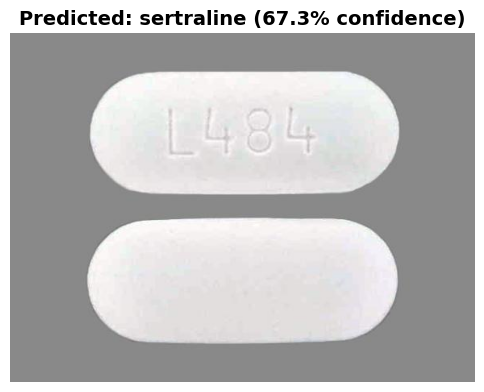


Top 3 Predictions:
1. sertraline: 67.25%
2. amoxicillin: 11.94%
3. acetaminophen: 6.49%

DRUG INTERACTION CHECK
Current medications: aspirin, lisinopril

⚠️  INTERACTION: sertraline + aspirin
   Severity: major
   SSRIs with aspirin increase bleeding risk. Monitor for bruising, bleeding, or gastrointestinal sympt...



In [ ]:
def complete_pill_analysis(image_path, model, class_names, drug_info_db, interactions_db):
    """Complete analysis pipeline: identify pill, show info, check interactions"""
    
  
    predicted_class, confidence, probs = predict_pill(image_path, model, class_names)
    
    print("="*80)
    print("PILL IDENTIFICATION REPORT")
    print("="*80)
    
   
    img = Image.open(image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class} ({confidence:.1f}% confidence)", 
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()
    
    
    print("\nTop 3 Predictions:")
    top_3_idx = np.argsort(probs)[-3:][::-1]
    for i, idx in enumerate(top_3_idx, 1):
        print(f"{i}. {class_names[idx]}: {probs[idx]*100:.2f}%")
    
    
    if predicted_class in drug_info_db:
        info = drug_info_db[predicted_class]
        print(f"\n{'='*80}")
        print(f"DRUG INFORMATION: {predicted_class.upper()}")
        print(f"{'='*80}")
        print(f"Generic: {info.get('generic_name', 'N/A')}")
        print(f"Class: {info.get('drug_class', 'N/A')}")
        print(f"Uses: {info.get('uses', 'N/A')}")
    
    
    current_medications = ["aspirin", "lisinopril"]  
    print(f"\n{'='*80}")
    print("DRUG INTERACTION CHECK")
    print(f"{'='*80}")
    print(f"Current medications: {', '.join(current_medications)}")
    
    interactions_found = False
    for med in current_medications:
        interaction = check_drug_interactions(predicted_class, med, interactions_db)
        if interaction:
            interactions_found = True
            print(f"\n⚠️  INTERACTION: {predicted_class} + {med}")
            print(f"   Severity: {interaction['severity']}")
            print(f"   {interaction['description'][:100]}...")
    
    if not interactions_found:
        print("\n✅ No known interactions detected")
    
    print("\n" + "="*80)


test_image = list((DATASET_PATH / medications[0]).glob("*.[jp][pn]g"))[0]
complete_pill_analysis(test_image, model, class_names, drug_info_db, interactions_db)

## 14. Summary and Recommendations

In [ ]:
print("="*80)
print("PROJECT SUMMARY")
print("="*80)

print(f"\n📊 Dataset:")
print(f"   • Total medications: {num_classes}")
print(f"   • Total images: {sum(image_counts.values())}")
print(f"   • Average per class: {sum(image_counts.values()) / num_classes:.1f}")

print(f"\n🤖 Model:")
print(f"   • Architecture: MobileNetV2 (Transfer Learning)")
print(f"   • Parameters: {model.count_params():,}")
print(f"   • Model size: {model_size_mb:.2f} MB")

print(f"\n📈 Performance:")
print(f"   • Test Accuracy: {test_accuracy*100:.2f}%")
print(f"   • Test Loss: {test_loss:.4f}")

print(f"\n💡 Recommendations:")
if test_accuracy < 0.50:
    print("   ⚠️  Low accuracy - Need more training data!")
    print("   • Collect 50-100 images per medication")
    print("   • Ensure variety in angles, lighting, backgrounds")
    print("   • Consider using NIH Pills Dataset or ePillID")
elif test_accuracy < 0.80:
    print("   • Good progress! Continue collecting data")
    print("   • Fine-tune hyperparameters")
    print("   • Add more augmentation strategies")
else:
    print("   ✅ Excellent accuracy!")
    print("   • Deploy to production")
    print("   • Monitor real-world performance")
    print("   • Collect edge cases for improvement")

print("\n" + "="*80)

PROJECT SUMMARY

📊 Dataset:
   • Total medications: 14
   • Total images: 146
   • Average per class: 10.4

🤖 Model:
   • Architecture: MobileNetV2 (Transfer Learning)
   • Parameters: 2,428,878
   • Model size: 23.56 MB

📈 Performance:
   • Test Accuracy: 34.78%
   • Test Loss: 4.5659

💡 Recommendations:
   ⚠️  Low accuracy - Need more training data!
   • Collect 50-100 images per medication
   • Ensure variety in angles, lighting, backgrounds
   • Consider using NIH Pills Dataset or ePillID

